# Lab 2. 폐루프 제어 — 관측 · Decoder · 액션

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kehdgus9434/sonic-vibe-coding-lab/blob/main/notebooks/lab2_closed_loop.ipynb)

**주제:** SONIC Decoder로 MuJoCo G1을 50 Hz로 제어하기

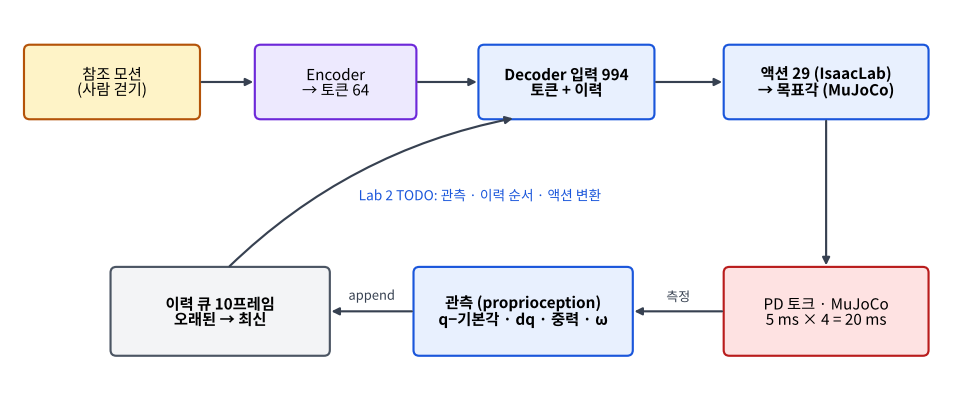

Lab 1의 토큰만으로는 로봇이 움직이지 않습니다. Decoder는 **토큰 + 최근 10프레임의 로봇 상태**를 보고 29개 관절 액션을 내고, 그 액션이 PD 제어로 바뀌어 시뮬레이터에 들어갑니다. 이 고리를 50 Hz로 계속 돌리는 것이 **폐루프 제어**입니다. 이번 Lab에서는 고리의 세 부분(관측, Decoder 입력, 액션 변환)을 채워 G1을 40초 동안 걷게 하고, **흔한 실수 네 가지**를 하나씩 넣어 무엇이 달라지는지 관찰합니다.

## 오늘의 산출물

1. 로봇 관측(proprioception) 만들기
2. Decoder 입력 994칸 (이력 순서)
3. 액션 → 관절 목표각 변환
4. 내 파이프라인으로 40초 걷기 + 영상
5. 흔한 실수 4가지의 영향 비교

## 실습 방식

- 대부분의 코드는 이미 작성되어 있습니다. **`TODO` 표시가 있는 셀의 빈칸만** 채우면 됩니다.
- `########### Answer #############` 사이의 `None` 또는 `_____`를 알맞은 값·식으로 바꾸세요. 채우지 않고 실행하면 `AssertionError: TODO …` 또는 `NameError: name '_____' is not defined`가 납니다.
- 각 TODO 아래의 `check.…` / `assert`가 바로 ✅/❌로 알려 줍니다. ❌이면 메시지를 읽고 빈칸을 다시 보세요.
- 막히면 AI(ChatGPT·Claude·Gemini, Colab의 Gemini)에게 **그 빈칸 하나**와 [`docs/01_contract.md`](https://github.com/kehdgus9434/sonic-vibe-coding-lab/blob/main/docs/01_contract.md)를 함께 주고 물어봐도 됩니다.
- 마지막의 **해석 질문**은 정답 제출용이 아니라 스스로 정리하기 위한 질문입니다.
- ⚠️ 이 실습의 어떤 출력도 실물 로봇에 보내지 않습니다.

# 0. 환경 설정

In [ ]:
#@title 실습 환경 준비 — 수정하지 말고 실행하세요 (처음 1–2분)
REPO = "https://github.com/kehdgus9434/sonic-vibe-coding-lab"
import os, sys, subprocess
from pathlib import Path
if Path("/content").exists():                              # Google Colab
    LAB_DIR = Path("/content/sonic-vibe-coding-lab")
    if not LAB_DIR.exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO, str(LAB_DIR)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(LAB_DIR / "requirements-colab.txt")], check=True)
else:                                                      # 로컬 Jupyter (저장소 안에서 실행)
    LAB_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(LAB_DIR)
sys.path.insert(0, str(LAB_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation as R
import sonic_lab
from sonic_lab import check, reference as ref, render, analysis
analysis.korean_font()
lab = sonic_lab.start()      # 공식 모델·로봇·걷기 샘플 준비 (lab.policy / lab.sim / lab.motion / lab.contract)

# 1. 로봇 상태 읽기 (관측)
MuJoCo의 `qpos`에는 기저(골반) 위치 3개, 기저 회전 쿼터니언 4개(`qpos[3:7]`, **w, x, y, z** 순서), 그다음 관절 각도가 들어 있습니다.

정책이 받는 관측은 다음과 같습니다.

| 키 | 크기 | 값 |
|---|---|---|
| `omega` | 3 | 기저 각속도 `qvel[3:6]` |
| `q` | 29 | 관절 각도 − **기본 자세 각도**, IsaacLab 순서 |
| `dq` | 29 | 관절 속도, IsaacLab 순서 |
| `action` | 29 | 직전 정책 출력 |
| `gravity` | 3 | 기저 좌표계에서 본 중력 방향 |

관절 순서는 두 가지입니다. MuJoCo 순서 벡터 `x_mj`를 IsaacLab 순서로 바꿀 때는 `x_mj[c.mujoco_to_isaaclab]`를 씁니다.

In [ ]:
c = lab.contract

def observation(sim, previous_action):
    d = sim.data
    # TODO 1: MuJoCo qpos[3:7]은 [w, x, y, z]입니다. scipy용 [x, y, z, w] 순서가 되도록 qpos의 인덱스 4개를 고르세요.
    # TODO 2: 관절 각도에서 무엇을 빼야 '기본 자세 대비 각도'가 될까요? (lab.contract에 있습니다)
    # Hint:
    # - qpos[3]=w, qpos[4]=x, qpos[5]=y, qpos[6]=z
    # - c.default: MuJoCo 순서 기본 자세 각도(rad)
    #
    ########### Answer #############
    base_xyzw = d.qpos[_____]
    q_rel = d.qpos[sim.qaddr] - _____
    ########### Answer #############
    return {
        "omega": d.qvel[3:6].copy(),
        "q": q_rel[c.mujoco_to_isaaclab],
        "dq": d.qvel[sim.vaddr][c.mujoco_to_isaaclab].copy(),
        "action": np.asarray(previous_action).copy(),
        "gravity": R.from_quat(base_xyzw).inv().apply([0, 0, -1]),
    }

check.observation(lab, observation)

# 상식으로 확인: 기본 자세로 똑바로 서 있으면?
lab.sim.reset(None, use_reference=False)
o = observation(lab.sim, np.zeros(29))
print("기본 자세에서 |q| 최대:", np.abs(o["q"]).max().round(6), "| 중력 방향:", o["gravity"].round(3))
lab.sim.reset(lab.motion)

# 2. Decoder 입력 994칸
Decoder 입력은 `토큰 64` 뒤에 다섯 가지 관측의 **최근 10프레임 이력**을 키별로 이어 붙인 것입니다.

```text
[ token 64 | omega 10×3 | q 10×29 | dq 10×29 | action 10×29 | gravity 10×3 ]  = 994
```

이력은 길이 10인 큐(deque)에 `append`로 쌓입니다. 그래서 **마지막 원소가 가장 최근** 프레임입니다. 각 블록 안에서는 **오래된 프레임 → 최신 프레임** 순서로 넣어야 합니다(학습 때와 같은 순서).

In [ ]:
HISTORY_KEYS = ["omega", "q", "dq", "action", "gravity"]

def decoder_obs(token, history):
    # TODO 3: history를 '오래된 → 최신' 순서의 리스트로 만드세요.
    # Hint:
    # - history[0]이 가장 오래된 것, history[-1]이 가장 최근 것입니다.
    # - list(x)와 list(reversed(x)) 중 무엇이 필요할까요?
    #
    ########### Answer #############
    frames = _____
    ########### Answer #############
    parts = [np.asarray(token, np.float32).reshape(64)]
    for key in HISTORY_KEYS:
        parts.append(np.asarray([f[key] for f in frames]).reshape(-1))
    return np.concatenate(parts).astype(np.float32)

check.decoder_obs(lab, decoder_obs)

# 3. 액션 → 관절 목표각
Decoder 출력 29개는 **IsaacLab 순서**의 '기본 자세로부터의 변화량'입니다. 시뮬레이터에 넣으려면

1. **MuJoCo 순서**로 재배열하고
2. 관절별 `scale`을 곱한 뒤
3. **기본 자세 각도**에 더합니다.

```text
target_mj = default + action_il[isaaclab_to_mujoco] × scale
```

In [ ]:
def action_to_target(action_il, contract):
    # TODO 4: IsaacLab 순서 → MuJoCo 순서로 바꾸는 배열을 고르세요 (contract.isaaclab_to_mujoco / contract.mujoco_to_isaaclab)
    # TODO 5: 변화량을 더할 출발점(기본 자세)을 채우세요.
    # Hint:
    # - a_mj = a_il[isaaclab_to_mujoco]  (계약서 2절)
    #
    ########### Answer #############
    action_mj = np.asarray(action_il)[_____]
    target = _____ + action_mj * contract.scale
    ########### Answer #############
    return target

check.action_to_target(lab, action_to_target)

# 4. 내 파이프라인으로 40초 걷기
세 함수를 묶어 폐루프에 넣습니다. 나머지(Encoder 입력, PD 토크 계산, 물리 시뮬레이션)는 준비된 코드가 처리합니다.
같은 조건에서 참조 구현과 결과가 **완전히 같으면** 세 부분이 모두 맞게 채워진 것입니다.

In [ ]:
class MyPipeline:
    def observation(self, sim, previous_action):
        return observation(sim, previous_action)
    def decoder_obs(self, token, history):
        return decoder_obs(token, history)
    def action_to_target(self, action, contract):
        return action_to_target(action, contract)

mine = ref.run_physics(lab.sim, lab.policy, lab.motion, mode=2, pipeline=MyPipeline(), verbose=True)
reference = ref.run_physics(lab.sim, lab.policy, lab.motion, mode=2)
display(analysis.table({"내 파이프라인": mine, "참조 구현": reference}))

In [ ]:
# 영상 (GPU 런타임이면 EGL, CPU면 OSMesa 소프트웨어 렌더링 · 6초, 1분 내외)
video = render.mesh_video(lab, mine[1], "outputs/lab2_my_pipeline.mp4", label="my pipeline / mode 2", seconds=6)
render.show(video or render.skeleton_video(lab, mine[1], "outputs/lab2_my_pipeline_skeleton.mp4", title="my pipeline", seconds=6))

# 5. 흔한 실수 4가지를 일부러 넣어 보기
실제 연구 과정(원본 05–07번 노트북)에서 나왔던 실수들입니다. **모두 에러 없이 실행됩니다.** 하나씩 켜서 무엇이 달라지는지 관찰하세요.

| 실수 | 들어가는 곳 |
|---|---|
| 기본각 오프셋 누락 | 관측 `q`에서 `default`를 빼지 않음 |
| 쿼터니언 순서 혼동 | `qpos[3:7]`(wxyz)를 그대로 xyzw로 사용 |
| 이력 순서 반대 | Decoder 입력에 최신 → 오래된 순서 |
| 관절 재배열 방향 반대 | 액션에 `mujoco_to_isaaclab` 사용 |

In [ ]:
# TODO 6: 관찰하고 싶은 실수를 True로 바꾸세요. (정답 없음 — 여러 개를 켜면 각각 따로 실행하고, 전부 켠 경우도 실행합니다)
#
########### Answer #############
MISTAKES = {
    "기본각 오프셋 누락": False,
    "쿼터니언 순서 혼동": False,
    "이력 순서 반대": False,
    "관절 재배열 방향 반대": False,
}
########### Answer #############
assert any(MISTAKES.values()), "TODO 6: 최소 하나를 True로 바꾸세요."

class Mistaken(MyPipeline):
    def __init__(self, on):
        self.on = set(on)
    def observation(self, sim, prev):
        o = super().observation(sim, prev)
        if "기본각 오프셋 누락" in self.on:
            o["q"] = sim.data.qpos[sim.qaddr][c.mujoco_to_isaaclab]
        if "쿼터니언 순서 혼동" in self.on:
            o["gravity"] = R.from_quat(sim.data.qpos[3:7]).inv().apply([0, 0, -1])
        return o
    def decoder_obs(self, token, history):
        return super().decoder_obs(token, list(reversed(list(history))) if "이력 순서 반대" in self.on else history)
    def action_to_target(self, action, contract):
        if "관절 재배열 방향 반대" in self.on:
            return contract.default + np.asarray(action)[contract.mujoco_to_isaaclab] * contract.scale
        return super().action_to_target(action, contract)

chosen = [k for k, v in MISTAKES.items() if v]
runs = {"실수 없음": ref.run_physics(lab.sim, lab.policy, lab.motion, 2, max_frames=500, pipeline=MyPipeline())}
for k in chosen:
    runs[k] = ref.run_physics(lab.sim, lab.policy, lab.motion, 2, max_frames=500, pipeline=Mistaken([k]))
if len(chosen) > 1:
    runs["선택한 실수 전부"] = ref.run_physics(lab.sim, lab.policy, lab.motion, 2, max_frames=500, pipeline=Mistaken(chosen))
display(analysis.table(runs))
analysis.plot(runs, lab);

In [ ]:
# 가장 마지막 조건의 움직임 (골격, 5초)
label = list(runs)[-1]
render.show(render.skeleton_video(lab, runs[label][1], "outputs/lab2_mistake.mp4", title=label, seconds=5))

# 6. Lab 2 정리
```text
관측(q − 기본각, 중력 방향, …) → 이력 10프레임(오래된 → 최신)
→ [토큰 + 이력] 994 → Decoder → 액션 29 (IsaacLab)
→ 재배열(MuJoCo) × scale + 기본각 → PD 토크 → MuJoCo  … 50 Hz 반복
```

## 해석 질문
1. 내 파이프라인과 참조 구현의 결과(관절 오차 등)는 완전히 같았나요? 같다면 그것이 무엇을 보장하나요?
2. 네 가지 실수 중 로봇을 가장 빨리 넘어뜨린 것은? 왜 그 실수가 가장 치명적일까요?
3. **넘어지지 않았는데도** 무언가 나빠진 실수가 있었나요? 완주 여부만 봤다면 그 실수를 알아챌 수 있었을까요?
4. 에러 없이 실행되는 실수를 미리 잡으려면, 정답 코드 없이 어떤 간단한 확인을 할 수 있을까요? (예: 1번 셀 아래의 '상식으로 확인')